Loading datasets …
  Glass loaded  ✓
  Thyroid loaded  ✓
Datasets ready: ['Iris', 'Wine', 'BreastCancer', 'Glass', 'Thyroid']

  [Iris]  C* = 2
  [Wine]  C* = 3
  [BreastCancer]  C* = 2
  [Glass]  C* = 5
  [Thyroid]  C* = 3

Dataset              N    d  True C    C*
--------------------------------------------------
Iris               150    4       3     2
Wine               178   13       3     3
BreastCancer       569   30       2     2
Glass              214    9       6     5
Thyroid            215    5       3     3


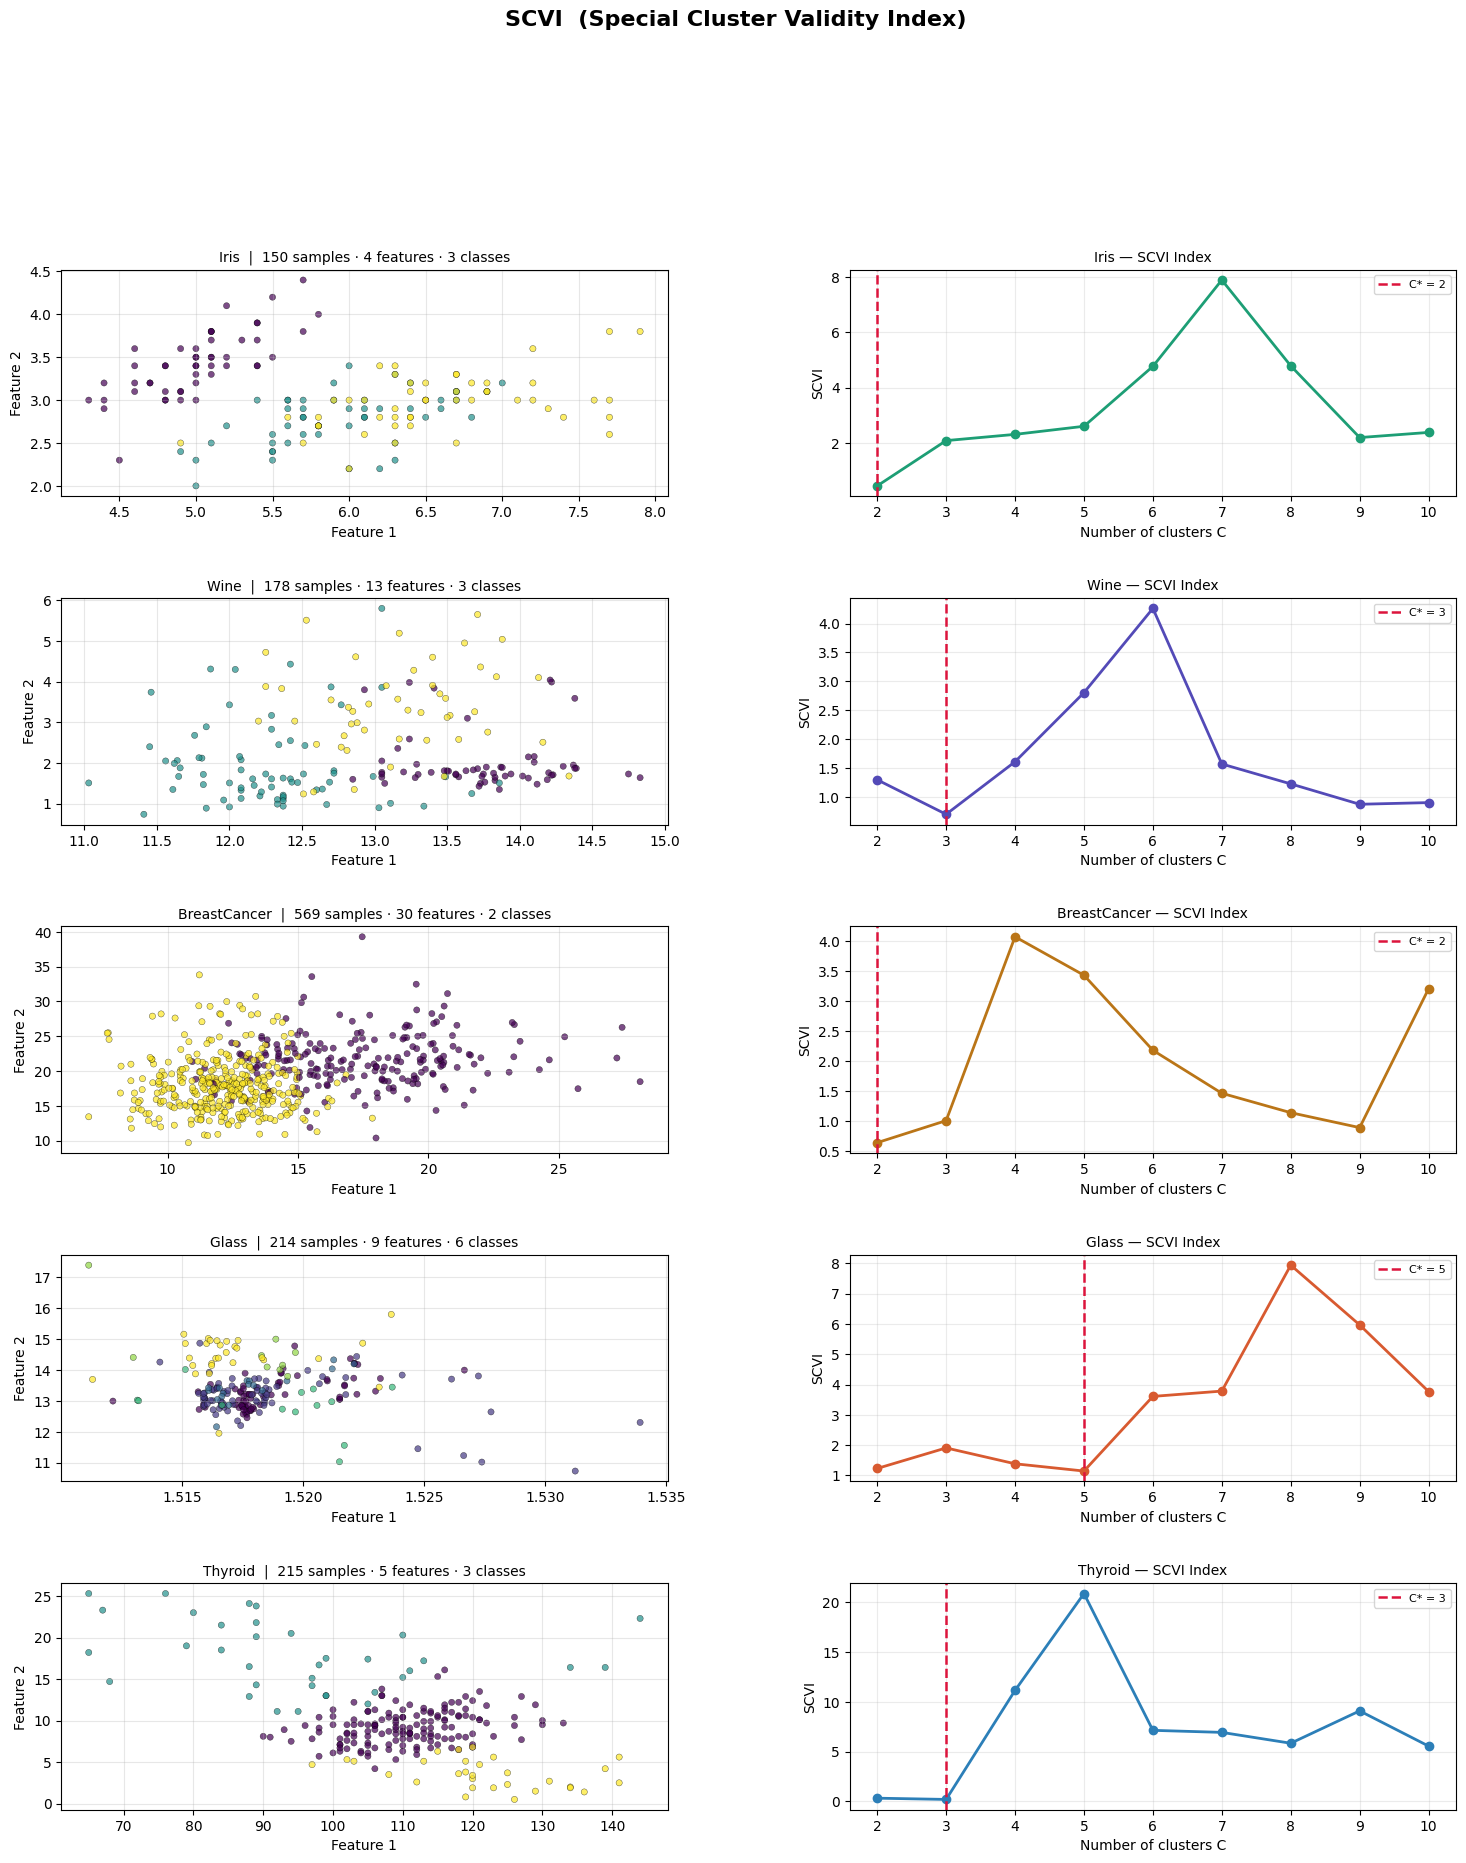


Sensitivity analysis (m ∈ [1.5 … 2.5]) …

  Sensitivity — C* across m values
m             1.5  1.7  1.9  2.1  2.3  2.5
Dataset                                   
BreastCancer    3    3    2    2    2    2
Glass           5    6    6    6    6    5
Iris            2    2    2    2    2    2
Thyroid         2    3    3    3    3    3
Wine            6    3    3    3   10    3


In [ ]:
%matplotlib inline
!pip install openpyxl -q

import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
from itertools import combinations
import warnings; warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris, load_wine, load_breast_cancer

# ── FCM ──────────────────────────────────────────────────────────────────────
def fcm(X, c, m=2.0, max_iter=150, eps=1e-4, seed=42):
    rng = np.random.default_rng(seed); n, d = X.shape
    U = rng.dirichlet(np.ones(c), size=n).T
    for _ in range(max_iter):
        Um = U**m; V = (Um @ X) / Um.sum(axis=1, keepdims=True)
        diff = X[:, None, :] - V[None, :, :]
        dist2 = np.maximum((diff**2).sum(axis=2).T, 1e-12)
        U_new = dist2**(-2.0/(m-1)); U_new /= U_new.sum(axis=0)
        if np.max(np.abs(U_new - U)) < eps: U = U_new; break
        U = U_new
    return U, V

# ── Three components ──────────────────────────────────────────────────────────
def compute_disp(X, U, V, m):
    mu_X = X.mean(0); std_X = X.std(0)
    mu_safe = np.where(np.abs(mu_X) < 1e-10, 1e-10, mu_X)
    denom = max(np.max(np.abs(std_X / mu_safe)), 1e-10)
    Um = U**m; pw = np.maximum(Um.sum(1), 1e-10); max_cv = 0
    for i in range(U.shape[0]):
        diff = X - V[i]; var_i = (Um[i,:,None]*diff**2).sum(0)/pw[i]
        vi_s = np.where(np.abs(V[i])<1e-10, 1e-10, V[i])
        max_cv = max(max_cv, np.max(np.abs(np.sqrt(var_i)/vi_s)))
    return max_cv / denom

def compute_overlap(U):
    max_ov = 0
    for l, r in combinations(range(U.shape[0]), 2):
        ov = np.minimum(U[l], U[r]).sum()
        if ov > max_ov: max_ov = ov
    return max_ov

def compute_separation(U, V):
    f = U.sum(1)          # fi = sum of memberships for cluster i
    c = len(f)
    if c < 2: return 0.0
    vals = [
        np.sum((V[i] - V[j])**2) / max(f[i] + f[j], 1e-10)
        for i, j in combinations(range(c), 2)
    ]
    return float(np.min(vals))

# ── SCVI ──────────────────────────────────────────────────────────────────────
def scvi(X, c_min=2, c_max=None, m=2.0, n_runs=3, seed=42):
    n = X.shape[0]
    if c_max is None: c_max = max(c_min+1, int(np.floor(np.sqrt(n))))
    c_max = min(c_max, n-1); C_range = list(range(c_min, c_max+1))
    da, oa, sa = np.zeros(len(C_range)), np.zeros(len(C_range)), np.zeros(len(C_range))
    Ub, Vb = {}, {}
    for idx, c in enumerate(C_range):
        best = np.inf; bU = bV = None
        for run in range(n_runs):
            U, V = fcm(X, c, m=m, seed=seed+run*17)
            obj = ((U.T**m)*((X[:,None,:]-V[None,:,:])**2).sum(2)).sum()
            if obj < best: best, bU, bV = obj, U.copy(), V.copy()
        Ub[c], Vb[c] = bU, bV
        da[idx], oa[idx], sa[idx] = compute_disp(X,bU,bV,m), compute_overlap(bU), compute_separation(bU,bV)
    def sn(a): mx=a.max(); return a/mx if mx>1e-10 else np.ones_like(a)
    dn, on, sep_n = sn(da), sn(oa), sn(sa)
    vi = (dn+on)/np.where(sep_n<1e-10, 1e-10, sep_n)
    bi = np.argmin(vi); Cs = C_range[bi]
    return dict(C_range=C_range, disp=da, overlap=oa, sep=sa,
                disp_n=dn, overlap_n=on, sep_n=sep_n, scvi=vi,
                C_star=Cs, U_star=Ub[Cs], V_star=Vb[Cs])

# ── Dataset loader ────────────────────────────────────────────────────────────
def load_datasets():
    d = {}

    iris = load_iris()
    d['Iris'] = dict(X=iris.data, y=iris.target, true_C=3,
                     desc='150 samples · 4 features · 3 classes')

    wine = load_wine()
    d['Wine'] = dict(X=wine.data, y=wine.target, true_C=3,
                     desc='178 samples · 13 features · 3 classes')

    bc = load_breast_cancer()
    d['BreastCancer'] = dict(X=bc.data, y=bc.target, true_C=2,
                             desc='569 samples · 30 features · 2 classes')

    try:
        g = pd.read_csv(
            'https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data',
            header=None)
        d['Glass'] = dict(X=g.iloc[:,1:-1].values.astype(float),
                          y=g.iloc[:,-1].values, true_C=6,
                          desc='214 samples · 9 features · 6 classes')
        print('  Glass loaded  ✓')
    except Exception as e:
        print(f'  Glass unavailable: {e}')

    try:
        t = pd.read_csv(
            'https://archive.ics.uci.edu/ml/machine-learning-databases/thyroid-disease/new-thyroid.data',
            header=None)
        d['Thyroid'] = dict(X=t.iloc[:,1:].values.astype(float),
                            y=t.iloc[:,0].values.astype(int), true_C=3,
                            desc='215 samples · 5 features · 3 classes')
        print('  Thyroid loaded  ✓')
    except Exception as e:
        print(f'  Thyroid unavailable: {e}')

    return d

# ── Sensitivity analysis ──────────────────────────────────────────────────────
def sensitivity(datasets, m_vals=[1.5, 1.7, 1.9, 2.1, 2.3, 2.5]):
    rows = []
    for name, ds in datasets.items():
        X = StandardScaler().fit_transform(ds['X'])
        for mv in m_vals:
            r = scvi(X, c_max=min(10, X.shape[0]-1), m=mv, n_runs=2)
            rows.append(dict(Dataset=name, m=mv, C_star=r['C_star']))
    df = pd.DataFrame(rows)
    print('\n' + '='*55)
    print('  Sensitivity — C* across m values')
    print('='*55)
    print(df.pivot(index='Dataset', columns='m', values='C_star').to_string())
    print('='*55)
    return df

# ── Plot ──────────────────────────────────────────────────────────────────────
def plot_results(datasets, results):
    n   = len(datasets)
    fig = plt.figure(figsize=(18, 4*n))
    gs  = gridspec.GridSpec(n, 2, hspace=0.45, wspace=0.3)
    colors = {'Iris':'#1D9E75', 'Wine':'#534AB7', 'Glass':'#D85A30',
              'BreastCancer':'#BA7517', 'Thyroid':'#2C7FB8'}
    for row, (name, ds) in enumerate(datasets.items()):
        res = results[name]; X = ds['X']; y = ds['y']; col = colors.get(name, '#888')

        # Left — scatter of first two features
        ax = fig.add_subplot(gs[row, 0])
        ax.scatter(X[:,0], X[:,1], c=y, cmap='viridis', s=20,
                   alpha=0.7, edgecolors='k', linewidths=0.3)
        ax.set_title(f'{name}  |  {ds["desc"]}', fontsize=10)
        ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2')
        ax.grid(True, alpha=0.3)

        # Right — SCVI curve
        ax = fig.add_subplot(gs[row, 1])
        CR = res['C_range']
        ax.plot(CR, res['scvi'], 'o-', color=col, lw=2, ms=6)
        ax.axvline(res['C_star'], color='crimson', ls='--', lw=1.8,
                   label=f"C* = {res['C_star']}")
        ax.set_title(f'{name} — SCVI Index', fontsize=10)
        ax.set_xlabel('Number of clusters C'); ax.set_ylabel('SCVI')
        ax.legend(fontsize=8); ax.grid(True, alpha=0.25)

    plt.suptitle('SCVI  (Special Cluster Validity Index)',
                 fontsize=16, fontweight='bold', y=1.01)
    plt.savefig("output.png")
    plt.tight_layout(); plt.show()

# ── Main ──────────────────────────────────────────────────────────────────────
def main():
    print('Loading datasets …')
    datasets = load_datasets()
    print(f'Datasets ready: {list(datasets.keys())}\n')

    results = {}
    for name, ds in datasets.items():
        print(f'  [{name}]', end='  ')
        X   = StandardScaler().fit_transform(ds['X'])
        res = scvi(X, c_max=min(10, X.shape[0]-1), m=2.0, n_runs=3)
        results[name] = res
        print(f"C* = {res['C_star']}")

    # Summary table
    print('\n' + '='*50)
    print(f"{'Dataset':<16}{'N':>6}{'d':>5}{'True C':>8}{'C*':>6}")
    print('-'*50)
    for name, ds in datasets.items():
        n, d = ds['X'].shape; star = results[name]['C_star']
        print(f"{name:<16}{n:>6}{d:>5}{ds['true_C']:>8}{star:>6}")
    print('='*50)

    # Plots
    plot_results(datasets, results)

    # Sensitivity
    print('\nSensitivity analysis (m ∈ [1.5 … 2.5]) …')
    sensitivity(datasets)

main()